# 4.2 · 线性模型：OLS · Ridge · Lasso

> 最经典的多因子模型就是**线性模型**：给每个因子学一个权重，加权合成预测。
> 它透明、稳健、可解释，是理解其他模型的基准，也是 Barra 等风险模型的核心。
> 本节你会发现：**朴素地用线性回归做选股会"翻车"，理解原因并掌握正确的打开方式**。

## 一、线性模型的数学形式

$$\hat{y}_{i,t} = \beta_0 + \beta_1 f_1 + \beta_2 f_2 + \dots + \beta_K f_K = X_{i,t}\beta$$

- 每个因子一个权重 $\beta_k$，预测值是因子的加权和；
- 正权重 = 因子越大越看好，负权重 = 反向。

**OLS（普通最小二乘）**通过最小化预测误差平方和求解：
$$\min_{\beta} \sum_{i,t} (y_{i,t} - X_{i,t}\beta)^2$$
闭式解：$\beta = (X^\top X)^{-1}X^\top y$。

## 二、先看朴素 OLS：用原始收益做标签

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from model_lab.data import build_panel, split_by_date, predict_ic
from model_lab.linear import fit_linear, rank_label, coef_table
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
df = build_panel(close, F['$volume'].unstack('instrument'),
                 F['$mkt_cap_ard'].unstack('instrument'),
                 F['$pe_ttm'].unstack('instrument'),
                 F['$pb_lf'].unstack('instrument'), 1)
tr, va, te = split_by_date(df, '2022-12-31', '2023-12-31')
# 来自不同大类的 5 个低相关因子
sel = ['SMB 小市值', 'EP 盈利收益率', 'REV5 短期反转', '低波60', '负偏度60']

def report(model, d, label='label'):
    pred = pd.Series(model.predict(d[sel]), index=d.index)
    ic = predict_ic(pred, d[label])
    return ic.mean(), ic.mean()/ic.std(), (ic > 0).mean()

m_ols = fit_linear(tr, sel, kind='ols', use_rank_label=False)
ic, ir, wr = report(m_ols, te)
print('朴素 OLS（原始标签）测试集：IC %.4f  IR %.4f  胜率 %.3f' % (ic, ir, wr))
print('注意：IC 为负——回归预测方向在样本外反了！')

[6344:MainThread](2026-10-30 01:23:15,777) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[6344:MainThread](2026-10-30 01:23:17,231) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[6344:MainThread](2026-10-30 01:23:17,232) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


朴素 OLS（原始标签）测试集：IC -0.0209  IR -0.0754  胜率 0.470
注意：IC 为负——回归预测方向在样本外反了！


## 三、为什么朴素 OLS 会"翻车"？

OLS 最小化的是**预测误差的平方（MSE），关注收益的"幅度"**；而选股评价看的是 **IC，关注"排序"**。两者目标不一致：

1. **极端收益主导**：次日收益有大量 ±10%（涨跌停），回归为了拟合这些极端值，会牺牲整体排序；
2. **因子相关（共线性）**：低波、EP、反转都在描述"低风险/被忽视"的股票，OLS 在相关因子间分配的权重符号很不稳定（系数表中低波、反转被给了负权重，与它们的单因子 IC 相反）；
3. **预测值被压缩**：弱信号下回归把预测收缩到极窄区间，排序主要由噪声决定。

> 一句话：**OLS 回答"预期收益是多少"，但我们更关心"谁排前面"。**

## 四、正则化：Ridge 与 Lasso

**Ridge（L2 正则）**在损失中加入权重平方惩罚，让权重更稳定、缓解共线性：
$$\min_{\beta} \sum (y-X\beta)^2 + \alpha\sum \beta_k^2$$
闭式解：$\beta = (X^\top X + \alpha I)^{-1}X^\top y$。

**Lasso（L1 正则）**加入权重绝对值惩罚，会让部分权重变为 0（**特征选择、稀疏**）：
$$\min_{\beta} \sum (y-X\beta)^2 + \alpha\sum |\beta_k|$$

但仅靠正则化、仍用原始标签，目标不一致的问题还在。下面做关键修正。

## 五、关键修正：让回归学"排序"（截面 rank 标签）

把标签在每个截面上转为**百分位排名**，回归目标就与 IC 一致：
- 消除了极端值，标签均匀分布在 (0,1)；
- 模型直接学习"股票的相对排序"。

这是线性多因子模型在选股中的常用做法。

In [2]:
# 用截面 rank 标签训练
m_ridge = fit_linear(tr, sel, kind='ridge', alpha=1.0, use_rank_label=True)
m_lasso = fit_linear(tr, sel, kind='lasso', alpha=1e-4, use_rank_label=True)
for name, m in [('Ridge(rank标签)', m_ridge), ('Lasso(rank标签)', m_lasso)]:
    ic, ir, wr = report(m, te)
    print('%-16s IC %.4f  IR %.4f  胜率 %.3f' % (name, ic, ir, wr))
print('\nRidge 因子权重（全部为正，方向正确）：')
print(coef_table(m_ridge, sel).round(4))

Ridge(rank标签)    IC 0.0282  IR 0.1321  胜率 0.555
Lasso(rank标签)    IC 0.0276  IR 0.1290  胜率 0.554

Ridge 因子权重（全部为正，方向正确）：
REV5 短期反转    0.0149
低波60         0.0062
SMB 小市值      0.0028
负偏度60        0.0022
EP 盈利收益率     0.0003
dtype: float64


## 六、完整对比：简单 vs 复杂

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


                   IC      IR
等权             0.0371  0.1578
IC加权           0.0319  0.1468
Ridge(rank标签)  0.0282  0.1321
Lasso(rank标签)  0.0276  0.1290
朴素OLS(原始标签)   -0.0209 -0.0754


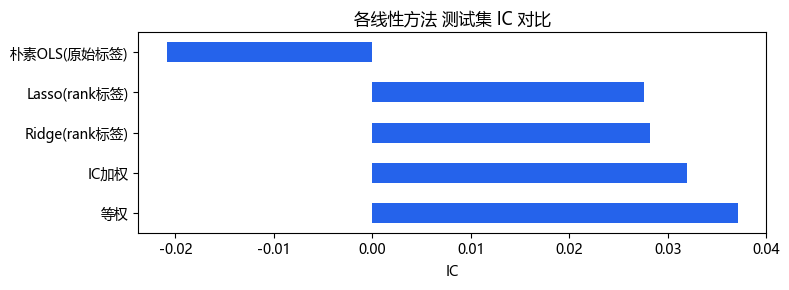

In [3]:
# 等权 & IC加权基准
equal = te[sel].mean(axis=1)
ic_eq = predict_ic(equal, te['label'])
def cs_ic(d, c):
    return d.groupby(level='datetime').apply(
        lambda x: x[c].corr(x['label'], method='spearman') if len(x)>10 else np.nan)
w_ic = np.array([cs_ic(tr, c).mean() for c in sel])
ic_iw = predict_ic(pd.Series(te[sel].values@w_ic, index=te.index), te['label'])

rows = {
    '等权': (ic_eq.mean(), ic_eq.mean()/ic_eq.std()),
    'IC加权': (ic_iw.mean(), ic_iw.mean()/ic_iw.std()),
    'Ridge(rank标签)': report(m_ridge, te)[:2],
    'Lasso(rank标签)': report(m_lasso, te)[:2],
    '朴素OLS(原始标签)': report(m_ols, te)[:2],
}
cmp = pd.DataFrame(rows, index=['IC','IR']).T.sort_values('IC', ascending=False)
print(cmp.round(4))

ax = cmp['IC'].plot(kind='barh', figsize=(8,3), color='#2563eb')
ax.set_title('各线性方法 测试集 IC 对比'); ax.set_xlabel('IC')
plt.tight_layout(); plt.show()

**结论（重要且真实）：**
- 在沪深300、弱信号、次日预测的场景下，**最简单的等权合成 IC 最高（0.037）**，正则化线性模型次之（0.028），朴素 OLS 因目标错配为负；
- 这说明：**简单稳健的方法常常跑赢复杂优化**，尤其在信号弱、噪声大、因子相关时；
- 线性模型的价值在于透明、可解释、稳定，是必做基准；要捕捉非线性、因子交互，需要树模型（4.3）和深度学习（4.4）。

## 七、小结与面试要点

- 线性模型 = 因子加权合成；OLS 闭式解 $(X^\top X)^{-1}X^\top y$。
- 朴素 OLS 选股翻车：目标是 MSE（幅度），被极端值和共线性主导，与 IC（排序）不一致。
- **Ridge（L2，稳权重）、Lasso（L1，稀疏选因子）**；把标签截面 rank 化，让回归学排序，方向才正确。
- 弱信号下等权常胜出；复杂模型必须先跑赢简单基准。

**面试高频：**
- OLS / Ridge / Lasso 的区别？（答：OLS 无正则，Ridge L2 收缩，Lasso L1 稀疏）
- 为什么线性回归做选股可能 IC 为负？（答：MSE 与 IC 目标不一致，极端值+共线性；用 rank 标签或截面回归修正）
- 共线性有什么危害？怎么解决？（答：权重不稳、符号乱；去冗余、Ridge、正交化）
- Lasso 为什么能做特征选择？（答：L1 惩罚使部分系数恰好为 0）

## 动手练习
1. 调整 Ridge 的 alpha，观察 IC 变化；
2. 用全部 13 个因子（含高相关）做 Ridge，对比 5 因子结果；
3. 把标签改成 5 日收益，重新拟合。

---
下一节 **4.3 LightGBM 树模型：量化选股的主力，特征重要性与非线性**。